# So sánh các thuật toán phân lớp trên hai bộ đặc trưng

**BTL Khai phá dữ liệu – HK261.**

Notebook này so sánh bốn thuật toán phân lớp trên cùng một quy trình, với hai bộ đặc trưng trích từ video:

| Bộ đặc trưng | Nguồn | Ghi chú |
|---|---|---|
| **Đóng băng** | EfficientNet-B0 học trước trên ImageNet (`extract-features`) | CNN chưa từng thấy video ký hiệu |
| **Tinh chỉnh** | EfficientNet-B0 đã tinh chỉnh trong CNN-LSTM giai đoạn B (`extract_finetuned`) | CNN đã học trên fold 1–4 |

Mỗi video có 16 vector 1.280 chiều (một vector mỗi khung), được gộp thành một vector 2.560 chiều bằng trung bình và độ lệch chuẩn theo thời gian (cách gộp F2, tốt nhất trong notebook SVM).

Câu hỏi chính: **chất lượng đặc trưng hay thuật toán phân lớp quyết định kết quả nhiều hơn?**

**Quy trình đánh giá**: chọn tham số bằng cross-validation 4 lần trên fold 1–4 với tiêu chí Macro F1; đánh giá một lần trên fold 0 (555 video); huấn luyện lại trên cả 2.772 video để ghi file nộp AIChallenge (tập private).

**Lưu ý:** với bộ đặc trưng tinh chỉnh, CNN đã học chính các video fold 1–4, nên điểm cross-validation trên fold 1–4 rất lạc quan và chỉ dùng để chọn tham số. Fold 0 (CNN chỉ dùng để chọn epoch dừng) và tập private là đánh giá khách quan.

In [1]:
import os, sys, json, time, shutil, tempfile, warnings, zipfile, unicodedata
from pathlib import Path

warnings.filterwarnings('ignore', category=SyntaxWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, top_k_accuracy_score,
                             roc_auc_score)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='A worker stopped while some jobs')
SEED = 42
VAL_FOLD = 0
N_CLASSES = 100
QUICK = os.environ.get('QUICK', '0') == '1'
N_JOBS = int(os.environ.get('N_JOBS', '-1'))
WANDB_PROJECT = 'dm-sign-language'

ROOT = Path(os.environ.get('PROJECT_ROOT', Path.cwd().parents[1]))
FROZEN_DIR = Path(os.environ.get('FROZEN_DIR', ROOT / 'models' / 'features'))
FT_DIR = Path(os.environ.get('FT_DIR', ROOT / 'models' / 'features_ft'))
CKPT_B = Path(os.environ.get('CKPT_B', ROOT / 'models' / 'cnn_lstm' / 'output' / 'cnn_lstm_B.pth'))
OUT = Path(os.environ.get('OUT_DIR', ROOT / 'models' / 'classical' / 'output'))
OUT.mkdir(parents=True, exist_ok=True)


def rel(path):
    return path.relative_to(ROOT) if path.is_relative_to(ROOT) else path


for p in [FROZEN_DIR / 'feat_train.npy', FT_DIR / 'feat_ft_train.npy']:
    assert p.exists(), f'Không tìm thấy {p}'
print('Đặc trưng đóng băng:', rel(FROZEN_DIR))
print('Đặc trưng tinh chỉnh:', rel(FT_DIR))
print('Output              :', rel(OUT), '| QUICK =', QUICK)

Đặc trưng đóng băng: models/features
Đặc trưng tinh chỉnh: models/features_ft
Output              : models/classical/output | QUICK = False


In [2]:
try:
    import wandb
except ImportError:
    wandb = None
api_key = os.environ.get('WANDB_API_KEY')
WANDB_MODE = 'online' if api_key else 'offline'
run = None
if wandb is not None:
    os.environ['WANDB_DIR'] = str(OUT)
    os.environ['WANDB_SILENT'] = 'true'
    if api_key:
        wandb.login(key=api_key)
    run = wandb.init(project=WANDB_PROJECT, name='classical-comparison', job_type='classical', mode=WANDB_MODE,
                     config={'model': 'classical', 'pooling': 'F2', 'seed': SEED, 'val_fold': VAL_FOLD, 'quick': QUICK})
print('wandb:', WANDB_MODE if wandb is not None else 'chưa cài – bỏ qua')

wandb: offline


## 1. Đọc đặc trưng và gộp theo thời gian

Thứ tự dòng của mọi file đặc trưng khớp `manifest_clean.csv` (train) và `test_manifest.csv` (public, private). Nhãn và fold lấy từ manifest; tên lớp ghi vào file nộp lấy từ `label_names.json` (dạng Unicode NFD).

In [3]:
manifest = pd.read_csv(FROZEN_DIR / 'manifest_clean.csv')
test_manifest = pd.read_csv(FROZEN_DIR / 'test_manifest.csv')
label_names = json.load(open(FROZEN_DIR / 'label_names.json', encoding='utf-8'))
display_names = manifest.drop_duplicates('label_idx').set_index('label_idx').cls.sort_index().tolist()
public_rows = test_manifest[test_manifest.split == 'public_test'].reset_index(drop=True)
private_rows = test_manifest[test_manifest.split == 'private_test'].reset_index(drop=True)
assert (pd.read_csv(FT_DIR / 'manifest_clean.csv').file == manifest.file).all()

y = manifest.label_idx.values
fold = manifest.fold.values
cv_mask, val_mask = fold != VAL_FOLD, fold == VAL_FOLD


def pool_f2(F):
    F = F.astype(np.float32)
    return np.concatenate([F.mean(1), F.std(1)], axis=1)


FEATURE_SETS = {'Đóng băng': (FROZEN_DIR, 'feat'), 'Tinh chỉnh': (FT_DIR, 'feat_ft')}
X = {}
for name, (d, prefix) in FEATURE_SETS.items():
    X[name] = {split: pool_f2(np.load(d / f'{prefix}_{split}.npy')) for split in ['train', 'public', 'private']}
    assert len(X[name]['train']) == len(manifest)
    assert len(X[name]['public']) == len(public_rows) and len(X[name]['private']) == len(private_rows)
    print(f"{name:10s}: train {X[name]['train'].shape} | public {X[name]['public'].shape} | private {X[name]['private'].shape}")
print('Train (fold 1–4):', cv_mask.sum(), '| validation (fold 0):', val_mask.sum())

Đóng băng : train (2772, 2560) | public (1630, 2560) | private (2859, 2560)
Tinh chỉnh: train (2772, 2560) | public (1630, 2560) | private (2859, 2560)
Train (fold 1–4): 2217 | validation (fold 0): 555


## 2. Thuật toán và lưới tham số

Mọi thuật toán dùng chung pipeline `StandardScaler → PCA (giữ 95% phương sai) → bộ phân lớp`. Pipeline được fit lại ở mỗi lần chia nên chuẩn hoá và PCA chỉ học từ phần train của lần chia đó.

| Thuật toán | Vai trò | Nguyên lý | Tìm tham số | Giá trị thử |
|---|---|---|---|---|
| Logistic Regression | baseline | mô hình tuyến tính, softmax cho 100 lớp, điều chuẩn L2 | GridSearchCV | C ∈ {0,01; 0,1; 1} |
| kNN | dựa trên khoảng cách | gán nhãn theo đa số trong k video gần nhất | GridSearchCV | k ∈ {1; 3; 5; 10; 20}, trọng số đều / theo khoảng cách, khoảng cách euclid / cosine |
| Random Forest | ensemble | trung bình nhiều cây quyết định, mỗi cây học trên mẫu bootstrap và tập con đặc trưng | RandomizedSearchCV, 8 cấu hình | số cây ∈ {300; 600}, độ sâu ∈ {không giới hạn; 30}, đặc trưng mỗi lần tách ∈ {√d; 5%}, lá tối thiểu ∈ {1; 2} |
| SVM tuyến tính | lề cực đại | siêu phẳng tách lớp với lề lớn nhất, một-đấu-phần-còn-lại | GridSearchCV | C ∈ {0,001; 0,01} |

Logistic Regression, Random Forest và SVM dùng trọng số lớp `balanced`; kNN không hỗ trợ trọng số lớp.

In [4]:
MODELS = {
    'Logistic Regression': (LogisticRegression(class_weight='balanced', max_iter=3000), GridSearchCV,
                            {'clf__C': [0.01, 0.1, 1]}),
    'kNN': (KNeighborsClassifier(), GridSearchCV,
            {'clf__n_neighbors': [1, 3, 5, 10, 20], 'clf__weights': ['uniform', 'distance'],
             'clf__metric': ['euclidean', 'cosine']}),
    'Random Forest': (RandomForestClassifier(class_weight='balanced_subsample', random_state=SEED, n_jobs=1),
                      RandomizedSearchCV,
                      {'clf__n_estimators': [300, 600], 'clf__max_depth': [None, 30],
                       'clf__max_features': ['sqrt', 0.05], 'clf__min_samples_leaf': [1, 2]}),
    'SVM tuyến tính': (LinearSVC(class_weight='balanced', max_iter=5000, random_state=SEED), GridSearchCV,
                       {'clf__C': [0.001, 0.01]}),
}
if QUICK:
    MODELS = {k: (est, search, {p: v[:1] for p, v in grid.items()}) for k, (est, search, grid) in MODELS.items()}
    MODELS['Random Forest'][2]['clf__n_estimators'] = [50]


def make_pipeline(est, memory=None):
    return Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=0.95, random_state=SEED)),
                     ('clf', clone(est))], memory=memory)


cv = PredefinedSplit(fold[cv_mask] - 1)
cv_rows, best_params, t_all = [], {}, time.time()
for feat in FEATURE_SETS:
    for model, (est, search, grid) in MODELS.items():
        cache = tempfile.mkdtemp()
        kw = {'n_iter': 8, 'random_state': SEED} if search is RandomizedSearchCV else {}
        gs = search(make_pipeline(est, cache), grid, scoring='f1_macro', cv=cv, n_jobs=N_JOBS, refit=False, **kw)
        t0 = time.time()
        gs.fit(X[feat]['train'][cv_mask], y[cv_mask])
        shutil.rmtree(cache, ignore_errors=True)
        res = gs.cv_results_
        for i, p in enumerate(res['params']):
            cv_rows.append({'feature': feat, 'model': model,
                            'params': ', '.join(f"{k.replace('clf__', '')}={v}" for k, v in p.items()),
                            'cv_f1_mean': res['mean_test_score'][i], 'cv_f1_std': res['std_test_score'][i],
                            'fit_seconds': res['mean_fit_time'][i]})
        best_params[(feat, model)] = gs.best_params_
        print(f'{feat:10s} | {model:20s} | {len(res["params"]):2d} cấu hình trong {time.time() - t0:5.0f}s | '
              f'CV F1 tốt nhất {gs.best_score_:.4f}')

cv_df = pd.DataFrame(cv_rows).sort_values(['feature', 'model', 'cv_f1_mean'], ascending=[True, True, False])
cv_df.to_csv(OUT / 'cv_results.csv', index=False)
print(f'Tổng thời gian tìm tham số: {(time.time() - t_all) / 60:.1f} phút')

Đóng băng  | Logistic Regression  |  3 cấu hình trong     6s | CV F1 tốt nhất 0.6624
Đóng băng  | kNN                  | 20 cấu hình trong     4s | CV F1 tốt nhất 0.6165
Đóng băng  | Random Forest        |  8 cấu hình trong   257s | CV F1 tốt nhất 0.5565
Đóng băng  | SVM tuyến tính       |  2 cấu hình trong    43s | CV F1 tốt nhất 0.6792
Tinh chỉnh | Logistic Regression  |  3 cấu hình trong     5s | CV F1 tốt nhất 0.8441
Tinh chỉnh | kNN                  | 20 cấu hình trong     5s | CV F1 tốt nhất 0.6901
Tinh chỉnh | Random Forest        |  8 cấu hình trong   275s | CV F1 tốt nhất 0.7225
Tinh chỉnh | SVM tuyến tính       |  2 cấu hình trong    46s | CV F1 tốt nhất 0.8407
Tổng thời gian tìm tham số: 10.7 phút


## 3. Đánh giá trên fold 0

Mỗi tổ hợp (bộ đặc trưng, thuật toán) với tham số tốt nhất được huấn luyện trên fold 1–4 và đánh giá một lần trên fold 0 bằng nhiều chỉ số:

- **Macro F1** (chỉ số chính của cuộc thi), **Macro precision**, **Macro recall**, **accuracy**;
- **Top-5 accuracy**: nhãn đúng nằm trong 5 dự đoán có điểm cao nhất;
- **ROC-AUC** một-đấu-phần-còn-lại, trung bình theo lớp.

Top-5 và ROC-AUC cần điểm cho từng lớp: Logistic Regression, kNN và Random Forest cho xác suất trực tiếp; SVM tuyến tính chỉ cho khoảng cách tới siêu phẳng nên được đổi sang dạng xác suất bằng softmax (thứ tự các lớp không đổi).

Dòng **CNN-LSTM (giai đoạn B)** được tính lại từ vector video và lớp phân loại của mô hình đã lưu, để so sánh trên cùng các chỉ số.

In [5]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def scores_of(pipe, Xs):
    clf = pipe.named_steps['clf']
    s = pipe.predict_proba(Xs) if hasattr(clf, 'predict_proba') else softmax(pipe.decision_function(Xs))
    assert list(clf.classes_) == list(range(N_CLASSES))
    return s


def all_metrics(y_true, s):
    pred = s.argmax(1)
    labels = list(range(N_CLASSES))
    return {'Macro F1': f1_score(y_true, pred, average='macro', labels=labels, zero_division=0),
            'Macro precision': precision_score(y_true, pred, average='macro', labels=labels, zero_division=0),
            'Macro recall': recall_score(y_true, pred, average='macro', labels=labels, zero_division=0),
            'Accuracy': accuracy_score(y_true, pred),
            'Top-5 accuracy': top_k_accuracy_score(y_true, s, k=5, labels=labels),
            'ROC-AUC': roc_auc_score(y_true, s, multi_class='ovr', average='macro', labels=labels)}


y_val = y[val_mask]
fold0_rows, val_pipes, val_scores = [], {}, {}
for (feat, model), params in best_params.items():
    est = MODELS[model][0]
    t0 = time.time()
    pipe = make_pipeline(est).set_params(**params).fit(X[feat]['train'][cv_mask], y[cv_mask])
    fit_s = time.time() - t0
    t0 = time.time()
    s = scores_of(pipe, X[feat]['train'][val_mask])
    val_pipes[(feat, model)], val_scores[(feat, model)] = pipe, s
    fold0_rows.append({'Bộ đặc trưng': feat, 'Thuật toán': model, **all_metrics(y_val, s),
                       'Huấn luyện (s)': fit_s, 'Dự đoán (s)': time.time() - t0,
                       'Tham số': ', '.join(f"{k.replace('clf__', '')}={v}" for k, v in params.items())})

import torch
ckpt = torch.load(CKPT_B, map_location='cpu', weights_only=False)
W = ckpt['state_dict']['head.cls.1.weight'].float().numpy()
b = ckpt['state_dict']['head.cls.1.bias'].float().numpy()
emb = np.load(FT_DIR / 'emb_ft_train.npy')
s_cnn = softmax(emb[val_mask] @ W.T + b)
fold0_rows.append({'Bộ đặc trưng': 'Tinh chỉnh', 'Thuật toán': 'CNN-LSTM (giai đoạn B)', **all_metrics(y_val, s_cnn),
                   'Huấn luyện (s)': np.nan, 'Dự đoán (s)': np.nan, 'Tham số': 'xem notebook cnn_lstm'})

fold0 = pd.DataFrame(fold0_rows)
fold0.to_csv(OUT / 'fold0_metrics.csv', index=False)
fold0.drop(columns='Tham số').round(4)

,Bộ đặc trưng,Thuật toán,Macro F1,Macro precision,Macro recall,Accuracy,Top-5 accuracy,ROC-AUC,Huấn luyện (s),Dự đoán (s)
0,Đóng băng,Logistic Regression,0.6800,0.6971,0.6885,0.8072,0.9081,0.9855,0.9080,0.0374
1,Đóng băng,kNN,0.6350,0.6537,0.6460,0.7622,0.7838,0.8218,0.6110,0.0325
2,Đóng băng,Random Forest,0.5966,0.6340,0.6004,0.7550,0.8342,0.9375,67.0161,0.1686
3,Đóng băng,SVM tuyến tính,0.6823,0.6994,0.6910,0.8090,0.9171,0.9645,19.0485,0.0285
4,Tinh chỉnh,Logistic Regression,0.8239,0.8410,0.8280,0.9045,0.9730,0.9989,0.6739,0.0291
5,Tinh chỉnh,kNN,0.7174,0.7342,0.7220,0.8054,0.8198,0.8600,0.5644,0.0308
6,Tinh chỉnh,Random Forest,0.6641,0.6943,0.6699,0.8360,0.9297,0.9869,47.3438,0.1092
7,Tinh chỉnh,SVM tuyến tính,0.8208,0.8303,0.8320,0.9081,0.9676,0.9929,19.3661,0.0279
8,Tinh chỉnh,CNN-LSTM (giai đoạn B),0.8589,0.8790,0.8638,0.9153,0.9694,0.9977,NaN,NaN


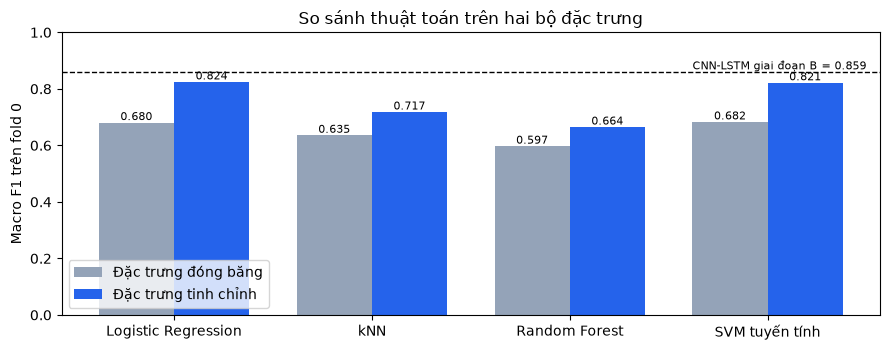

In [6]:
algos = list(MODELS)
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.38
for i, (feat, color) in enumerate([('Đóng băng', '#94a3b8'), ('Tinh chỉnh', '#2563eb')]):
    vals = [fold0.query('`Bộ đặc trưng` == @feat and `Thuật toán` == @a')['Macro F1'].item() for a in algos]
    bars = ax.bar(np.arange(len(algos)) + (i - 0.5) * w, vals, w, color=color, label=f'Đặc trưng {feat.lower()}')
    ax.bar_label(bars, fmt='%.3f', fontsize=8)
cnn = fold0.query('`Thuật toán` == "CNN-LSTM (giai đoạn B)"')['Macro F1'].item()
ax.axhline(cnn, ls='--', c='k', lw=1)
ax.text(len(algos) - 0.5, cnn + 0.01, f'CNN-LSTM giai đoạn B = {cnn:.3f}', ha='right', fontsize=8)
ax.set_xticks(range(len(algos))); ax.set_xticklabels(algos)
ax.set_ylabel('Macro F1 trên fold 0'); ax.set_ylim(0, 1); ax.legend(loc='lower left')
ax.set_title('So sánh thuật toán trên hai bộ đặc trưng')
fig.tight_layout(); fig.savefig(OUT / 'fold0_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. Diễn giải

**Mức quan trọng của nhóm đặc trưng (permutation importance).** Vector F2 gồm hai nửa: 1.280 chiều **trung bình** (hình dáng, tư thế xuất hiện trong video) và 1.280 chiều **độ lệch chuẩn** (mức độ thay đổi qua thời gian, tức chuyển động). Với mô hình tốt nhất của mỗi bộ đặc trưng, ta xáo trộn ngẫu nhiên toàn bộ một nửa giữa các video của fold 0 (phá liên hệ giữa nửa đó và nhãn) rồi đo Macro F1 giảm bao nhiêu; lặp lại 5 lần lấy trung bình. Nửa nào làm điểm giảm nhiều hơn thì mô hình dựa vào nửa đó nhiều hơn.

**F1 từng lớp.** So sánh F1 của cùng một thuật toán trên hai bộ đặc trưng để xem lớp nào được lợi nhiều nhất khi tinh chỉnh CNN.

In [7]:
rng = np.random.default_rng(SEED)
half = X['Đóng băng']['train'].shape[1] // 2
groups = {'Trung bình (hình dáng)': slice(0, half), 'Độ lệch chuẩn (chuyển động)': slice(half, 2 * half)}
best_algo = {feat: fold0[(fold0['Bộ đặc trưng'] == feat) & (fold0['Thuật toán'] != 'CNN-LSTM (giai đoạn B)')]
             .sort_values('Macro F1', ascending=False)['Thuật toán'].iloc[0] for feat in FEATURE_SETS}
imp_rows = []
for feat, model in best_algo.items():
    pipe, Xv = val_pipes[(feat, model)], X[feat]['train'][val_mask]
    base = f1_score(y_val, pipe.predict(Xv), average='macro')
    for gname, sl in groups.items():
        drops = []
        for _ in range(1 if QUICK else 5):
            Xp = Xv.copy()
            Xp[:, sl] = Xv[rng.permutation(len(Xv))][:, sl]
            drops.append(base - f1_score(y_val, pipe.predict(Xp), average='macro'))
        imp_rows.append({'Bộ đặc trưng': feat, 'Thuật toán': model, 'Nhóm đặc trưng bị xáo trộn': gname,
                         'Macro F1 giảm': np.mean(drops), 'Độ lệch chuẩn': np.std(drops)})
importance = pd.DataFrame(imp_rows)
importance.to_csv(OUT / 'group_importance.csv', index=False)
importance.round(4)

,Bộ đặc trưng,Thuật toán,Nhóm đặc trưng bị xáo trộn,Macro F1 giảm,Độ lệch chuẩn
0,Đóng băng,SVM tuyến tính,Trung bình (hình dáng),0.3068,0.0120
1,Đóng băng,SVM tuyến tính,Độ lệch chuẩn (chuyển động),0.5145,0.0113
2,Tinh chỉnh,Logistic Regression,Trung bình (hình dáng),0.4059,0.0264
3,Tinh chỉnh,Logistic Regression,Độ lệch chuẩn (chuyển động),0.5165,0.0204


In [8]:
algo = best_algo['Tinh chỉnh']
f1_cls = {feat: f1_score(y_val, val_scores[(feat, algo)].argmax(1), average=None, labels=range(N_CLASSES),
                         zero_division=0) for feat in FEATURE_SETS}
per_class = pd.DataFrame({'lớp': display_names, 'số video fold 0': np.bincount(y_val, minlength=N_CLASSES),
                          'F1 đóng băng': f1_cls['Đóng băng'], 'F1 tinh chỉnh': f1_cls['Tinh chỉnh']})
per_class['chênh lệch'] = per_class['F1 tinh chỉnh'] - per_class['F1 đóng băng']
per_class.to_csv(OUT / 'per_class_f1.csv', index=False)
print(f'{algo}: số lớp F1 tăng {int((per_class["chênh lệch"] > 0).sum())}, giảm {int((per_class["chênh lệch"] < 0).sum())}, '
      f'không đổi {int((per_class["chênh lệch"] == 0).sum())}')
print('\n10 lớp (có ít nhất 3 video ở fold 0) được lợi nhiều nhất khi tinh chỉnh CNN:')
print(per_class[per_class['số video fold 0'] >= 3].sort_values('chênh lệch', ascending=False).head(10)
      .round(3).to_string(index=False))

Logistic Regression: số lớp F1 tăng 56, giảm 10, không đổi 34

10 lớp (có ít nhất 3 video ở fold 0) được lợi nhiều nhất khi tinh chỉnh CNN:
      lớp  số video fold 0  F1 đóng băng  F1 tinh chỉnh  chênh lệch
      Đầu                7         0.471          1.000       0.529
 Bạn thân                3         0.500          1.000       0.500
     Uống                4         0.286          0.750       0.464
      Đẹp                3         0.000          0.400       0.400
   Xe đạp                3         0.400          0.800       0.400
 Thức dậy               10         0.600          0.947       0.347
  Bộ y tế                3         0.667          1.000       0.333
Bệnh viện                7         0.615          0.923       0.308
      Nói                4         0.571          0.857       0.286
       Đi                9         0.667          0.947       0.281


## 5. Huấn luyện lại trên cả 2.772 video và ghi file nộp

Mỗi tổ hợp được huấn luyện lại với tham số tốt nhất trên toàn bộ train. AIChallenge chấm trên tập private và đọc file `cv_submission.csv` trong file zip, nên dự đoán private được đóng gói thành `classical_<bộ đặc trưng>_<thuật toán>_submission.zip`. **Kiểm tra phụ:** 156 video public test giống hệt video train phải được đoán đúng gần hết.

In [9]:
md5_label = dict(zip(manifest.md5, manifest.label_idx))
dup = public_rows.md5.map(md5_label)
dup_mask = dup.notna().values
SLUG = {'Đóng băng': 'frozen', 'Tinh chỉnh': 'finetuned', 'Logistic Regression': 'logreg', 'kNN': 'knn',
        'Random Forest': 'rf', 'SVM tuyến tính': 'linsvm'}
sub_rows = []
for (feat, model), params in best_params.items():
    t0 = time.time()
    pipe = make_pipeline(MODELS[model][0]).set_params(**params).fit(X[feat]['train'], y)
    name = f'classical_{SLUG[feat]}_{SLUG[model]}'
    preds = {}
    for split, rows in [('private', private_rows), ('public', public_rows)]:
        preds[split] = pipe.predict(X[feat][split])
        sub = pd.DataFrame({'video_name': rows.file, 'label': [label_names[i] for i in preds[split]]})
        assert sub.video_name.is_unique and set(sub.label) <= set(label_names)
        assert all(unicodedata.normalize('NFD', s) == s for s in sub.label)
        sub.to_csv(OUT / f'{name}_{split}.csv', index=False, encoding='utf-8')
    with zipfile.ZipFile(OUT / f'{name}_submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
        z.write(OUT / f'{name}_private.csv', arcname='cv_submission.csv')
    counts = pd.Series(preds['private']).value_counts()
    sub_rows.append({'File nộp': f'{name}_submission.zip', 'Bộ đặc trưng': feat, 'Thuật toán': model,
                     'Số lớp dự đoán (private)': counts.size, 'Lớp nhiều nhất (số video)': int(counts.iloc[0]),
                     'Public trùng train đoán đúng': (preds['public'][dup_mask] == dup[dup_mask].astype(int).values).mean(),
                     'Thời gian (s)': round(time.time() - t0)})
submissions = pd.DataFrame(sub_rows)
submissions

,File nộp,Bộ đặc trưng,Thuật toán,Số lớp dự đoán (private),Lớp nhiều nhất (số video),Public trùng train đoán đúng,Thời gian (s)
0,classical_frozen_logreg_submission.zip,Đóng băng,Logistic Regression,93,191,1.0,1
1,classical_frozen_knn_submission.zip,Đóng băng,kNN,88,368,1.0,1
2,classical_frozen_rf_submission.zip,Đóng băng,Random Forest,93,120,1.0,91
3,classical_frozen_linsvm_submission.zip,Đóng băng,SVM tuyến tính,91,147,1.0,27
4,classical_finetuned_logreg_submission.zip,Tinh chỉnh,Logistic Regression,98,127,1.0,1
5,classical_finetuned_knn_submission.zip,Tinh chỉnh,kNN,96,176,1.0,1
6,classical_finetuned_rf_submission.zip,Tinh chỉnh,Random Forest,94,103,1.0,63
7,classical_finetuned_linsvm_submission.zip,Tinh chỉnh,SVM tuyến tính,99,110,1.0,25


## 6. Lưu kết quả và log

In [10]:
summary = {'fold0': fold0.drop(columns=['Huấn luyện (s)', 'Dự đoán (s)']).round(4).to_dict('records'),
           'best_algorithm': best_algo, 'group_importance': importance.round(4).to_dict('records'),
           'n_configs': int(len(cv_df)), 'quick': QUICK}
json.dump(summary, open(OUT / 'summary.json', 'w'), indent=2, ensure_ascii=False, default=str)

if run is not None:
    run.log({'cv_results': wandb.Table(dataframe=cv_df),
             'fold0_metrics': wandb.Table(dataframe=fold0.astype({'Huấn luyện (s)': float, 'Dự đoán (s)': float})),
             'group_importance': wandb.Table(dataframe=importance),
             'fold0_comparison': wandb.Image(str(OUT / 'fold0_comparison.png'))})
    run.summary.update({f"{r['Bộ đặc trưng']}/{r['Thuật toán']}/macro_f1": round(float(r['Macro F1']), 4)
                        for r in fold0_rows})
    run.finish()

for p in sorted(q for q in OUT.iterdir() if not q.name.startswith('.')):
    print(f'{p.name:48s}', 'thư mục' if p.is_dir() else f'{p.stat().st_size / 1e6:.2f} MB')

classical_finetuned_knn_private.csv              0.06 MB
classical_finetuned_knn_public.csv               0.03 MB
classical_finetuned_knn_submission.zip           0.02 MB
classical_finetuned_linsvm_private.csv           0.06 MB
classical_finetuned_linsvm_public.csv            0.03 MB
classical_finetuned_linsvm_submission.zip        0.02 MB
classical_finetuned_logreg_private.csv           0.06 MB
classical_finetuned_logreg_public.csv            0.03 MB
classical_finetuned_logreg_submission.zip        0.02 MB
classical_finetuned_rf_private.csv               0.06 MB
classical_finetuned_rf_public.csv                0.04 MB
classical_finetuned_rf_submission.zip            0.02 MB
classical_frozen_knn_private.csv                 0.06 MB
classical_frozen_knn_public.csv                  0.03 MB
classical_frozen_knn_submission.zip              0.02 MB
classical_frozen_linsvm_private.csv              0.06 MB
classical_frozen_linsvm_public.csv               0.03 MB
classical_frozen_linsvm_submiss

## 7. Kết quả trên AIChallenge

Macro F1 trên tập private (2.859 video), nộp ngày 24/11. Dòng CNN-LSTM lấy từ notebook `cnn_lstm`.

| Thuật toán | Đóng băng: fold 0 | Đóng băng: private | Tinh chỉnh: fold 0 | Tinh chỉnh: private |
|---|---|---|---|---|
| Logistic Regression | 0,680 | **0,340** | 0,824 | **0,662** |
| kNN | 0,635 | 0,195 | 0,717 | 0,509 |
| Random Forest | 0,597 | 0,153 | 0,664 | 0,439 |
| SVM tuyến tính | 0,682 | 0,297 | 0,821 | 0,641 |
| CNN-LSTM | 0,783 (A0) | 0,415 (A0) | 0,859 (B) | **0,687** (B) |

- **Bộ đặc trưng quyết định nhiều hơn thuật toán.** Đổi từ đặc trưng đóng băng sang đặc trưng tinh chỉnh làm điểm private của mọi thuật toán tăng 0,29–0,34; trong khi trên cùng một bộ đặc trưng, chênh lệch giữa thuật toán tốt nhất và kém nhất là 0,19–0,22.
- **Thứ hạng thuật toán giữ nguyên** giữa fold 0 và private: mô hình tuyến tính (Logistic Regression, SVM) > kNN > Random Forest.
- **kNN và Random Forest giảm mạnh hơn khi gặp video mới** (khoảng 0,44 với đặc trưng đóng băng, 0,21–0,23 với đặc trưng tinh chỉnh), so với mô hình tuyến tính (0,34–0,38 và 0,16–0,18). Hai thuật toán này dựa vào vùng lân cận hoặc ngưỡng trên từng chiều trong dữ liệu train, nên nhạy hơn khi phân bố đặc trưng của video test bị dịch chuyển.
- Logistic Regression trên đặc trưng tinh chỉnh (0,662) chỉ kém CNN-LSTM 0,025 điểm private, với thời gian huấn luyện khoảng 1 giây. Tuy nhiên bộ đặc trưng này được tạo ra từ chính CNN đã tinh chỉnh trong CNN-LSTM, nên đây là cách tái sử dụng biểu diễn đã học chứ không phải một mô hình độc lập.